# Customer Churn Prediction
## Random Forest and XGBoost Classification

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Dataset information
print("DATASET INFORMATION")
df.info()

# Missing values
print("\nMISSING VALUES")
display(df.isnull().sum().sort_values(ascending=False))

# Duplicate records
print("\nDUPLICATE ROWS:", df.duplicated().sum())

# Churn distribution
print("\nCHURN DISTRIBUTION")
display(df["Churn"].value_counts())

# Churn percentages
print("\nCHURN PERCENTAGES")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null  

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


DUPLICATE ROWS: 0

CHURN DISTRIBUTION


Churn
No     5174
Yes    1869
Name: count, dtype: int64


CHURN PERCENTAGES


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

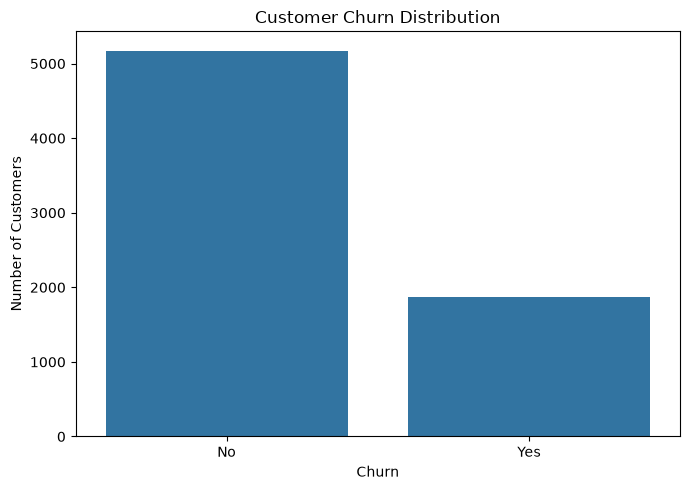

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../results/churn_distribution.png", dpi=300)
plt.show()

In [4]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

# Inspect affected rows
display(df[df["TotalCharges"].isnull()])

Missing TotalCharges after conversion: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [5]:
# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify the result
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nDataset shape:", df.shape)

Missing values after cleaning:
0

TotalCharges data type:
float64

Dataset shape: (7043, 21)


In [6]:
# Check column data types
print("Column data types:")
print(df.dtypes)

# Count numerical and categorical columns
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

print("\nNumerical columns:", len(numerical_cols))
print(list(numerical_cols))

print("\nCategorical columns:", len(categorical_cols))
print(list(categorical_cols))

Column data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

Numerical columns: 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: 17
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


C:\Users\H\AppData\Local\Temp\ipykernel_20488\286992150.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns


In [7]:
# Remove customerID because it is only an identifier
df = df.drop(columns=["customerID"])

# Separate input features (X) and target (y)
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Identify numerical and categorical features
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["str"]).columns.tolist()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", numerical_cols)
print("\nCategorical features:", categorical_cols)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

Testing churn distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
# Fit preprocessing on training data
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform testing data using the same preprocessing
X_test_prepared = preprocessor.transform(X_test)

print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

print("\nData type:", type(X_train_prepared))

Training data shape: (5634, 45)
Testing data shape: (1409, 45)

Data type: <class 'numpy.ndarray'>


In [11]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_prepared, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict churn labels
y_pred_rf = rf_model.predict(X_test_prepared)

# Predict churn probabilities
y_proba_rf = rf_model.predict_proba(X_test_prepared)[:, 1]

# Calculate evaluation metrics
print("Random Forest Performance")
print("-------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, pos_label="Yes"), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, pos_label="Yes"), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, pos_label="Yes"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance
-------------------------
Accuracy: 0.77
Precision: 0.559
Recall: 0.6337
F1-score: 0.594
ROC-AUC: 0.8225

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.82      0.84      1035
         Yes       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409



In [13]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [14]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [15]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [16]:
# Calculate class imbalance ratio
negative = (y_train == "No").sum()
positive = (y_train == "Yes").sum()

scale_pos_weight = negative / positive

print("Non-churning customers:", negative)
print("Churning customers:", positive)
print("Scale positive weight:", round(scale_pos_weight, 3))

Non-churning customers: 4139
Churning customers: 1495
Scale positive weight: 2.769


In [17]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

# Train the model
xgb_model.fit(X_train_prepared, y_train.map({"No": 0, "Yes": 1}))

print("XGBoost training completed!")

XGBoost training completed!


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict churn labels
y_pred_xgb = xgb_model.predict(X_test_prepared)

# Predict churn probabilities
y_proba_xgb = xgb_model.predict_proba(X_test_prepared)[:, 1]

# Convert predictions back to Yes/No
y_pred_xgb_labels = pd.Series(y_pred_xgb).map({
    0: "No",
    1: "Yes"
})

# Evaluate performance
print("XGBoost Performance")
print("-------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb_labels), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb_labels, pos_label="Yes"), 4))
print("Recall:", round(recall_score(y_test, y_pred_xgb_labels, pos_label="Yes"), 4))
print("F1-score:", round(f1_score(y_test, y_pred_xgb_labels, pos_label="Yes"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test.map({"No": 0, "Yes": 1}), y_proba_xgb), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_labels))

XGBoost Performance
-------------------
Accuracy: 0.7544
Precision: 0.5255
Recall: 0.7727
F1-score: 0.6255
ROC-AUC: 0.8419

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.75      0.82      1035
         Yes       0.53      0.77      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold stratified cross-validation configured!")

5-fold stratified cross-validation configured!


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Random Forest pipeline
rf_cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# XGBoost pipeline
xgb_cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        random_state=42,
        n_jobs=1
    ))
])

print("Random Forest and XGBoost CV pipelines created!")

Random Forest and XGBoost CV pipelines created!


In [21]:
# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    rf_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# XGBoost cross-validation
xgb_cv_scores = cross_val_score(
    xgb_cv_pipeline,
    X_train,
    y_train.map({"No": 0, "Yes": 1}),
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Display results
print("Random Forest CV scores:", rf_cv_scores.round(4))
print("Random Forest Mean ROC-AUC:", round(rf_cv_scores.mean(), 4))
print("Random Forest Std:", round(rf_cv_scores.std(), 4))

print("\nXGBoost CV scores:", xgb_cv_scores.round(4))
print("XGBoost Mean ROC-AUC:", round(xgb_cv_scores.mean(), 4))
print("XGBoost Std:", round(xgb_cv_scores.std(), 4))

Random Forest CV scores: [0.8159 0.8091 0.827  0.8205 0.8393]
Random Forest Mean ROC-AUC: 0.8223
Random Forest Std: 0.0103

XGBoost CV scores: [0.8387 0.8318 0.843  0.856  0.8524]
XGBoost Mean ROC-AUC: 0.8444
XGBoost Std: 0.0089


In [22]:
from sklearn.model_selection import RandomizedSearchCV

# XGBoost hyperparameter search space
xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 400, 500, 600],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0, 0.1, 0.2, 0.3],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

# Configure randomized search
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_cv_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("XGBoost hyperparameter search configured!")

XGBoost hyperparameter search configured!


In [23]:
# Run randomized hyperparameter search
xgb_random_search.fit(
    X_train,
    y_train.map({"No": 0, "Yes": 1})
)

print("\nXGBoost tuning completed!")

print("\nBest ROC-AUC:", round(xgb_random_search.best_score_, 4))

print("\nBest hyperparameters:")
print(xgb_random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

XGBoost tuning completed!

Best ROC-AUC: 0.8498

Best hyperparameters:
{'classifier__subsample': 0.7, 'classifier__reg_lambda': 10, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 5, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.7}


In [24]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "classifier__n_estimators": [200, 300, 400, 500, 600],
    "classifier__max_depth": [None, 10, 20, 30, 40],
    "classifier__min_samples_split": [2, 5, 10, 15],
    "classifier__min_samples_leaf": [1, 2, 4, 6],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_cv_pipeline,
    param_distributions=rf_param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Random Forest hyperparameter search configured!")

Random Forest hyperparameter search configured!


In [25]:
# Run Random Forest hyperparameter search
rf_random_search.fit(X_train, y_train)

print("\nRandom Forest tuning completed!")

print("\nBest ROC-AUC:", round(rf_random_search.best_score_, 4))

print("\nBest hyperparameters:")
print(rf_random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Random Forest tuning completed!

Best ROC-AUC: 0.8472

Best hyperparameters:
{'classifier__n_estimators': 400, 'classifier__min_samples_split': 15, 'classifier__min_samples_leaf': 6, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}


In [26]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Get best tuned models
best_rf = rf_random_search.best_estimator_
best_xgb = xgb_random_search.best_estimator_

# Random Forest predictions
rf_pred = best_rf.predict(X_test)
rf_proba = best_rf.predict_proba(X_test)[:, 1]

# XGBoost predictions
xgb_pred = best_xgb.predict(X_test)
xgb_proba = best_xgb.predict_proba(X_test)[:, 1]

# Convert XGBoost predictions to Yes/No
xgb_pred_labels = pd.Series(xgb_pred).map({0: "No", 1: "Yes"})

# Compare test performance
tuned_results = pd.DataFrame([
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, pos_label="Yes"),
        "Recall": recall_score(y_test, rf_pred, pos_label="Yes"),
        "F1-score": f1_score(y_test, rf_pred, pos_label="Yes"),
        "ROC-AUC": roc_auc_score(y_test, rf_proba)
    },
    {
        "Model": "Tuned XGBoost",
        "Accuracy": accuracy_score(y_test, xgb_pred_labels),
        "Precision": precision_score(y_test, xgb_pred_labels, pos_label="Yes"),
        "Recall": recall_score(y_test, xgb_pred_labels, pos_label="Yes"),
        "F1-score": f1_score(y_test, xgb_pred_labels, pos_label="Yes"),
        "ROC-AUC": roc_auc_score(
            y_test.map({"No": 0, "Yes": 1}), xgb_proba
        )
    }
])

display(tuned_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Tuned Random Forest,0.7523,0.5220,0.7941,0.6299,0.8416
1,Tuned XGBoost,0.7530,0.5226,0.8021,0.6329,0.8484


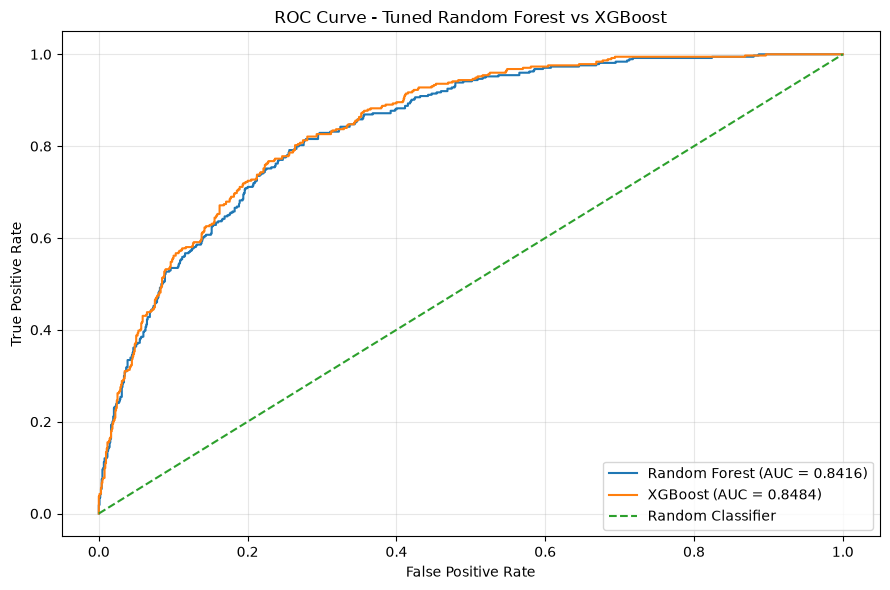

In [27]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Convert actual labels to binary
y_test_binary = y_test.map({"No": 0, "Yes": 1})

# Calculate ROC curves
rf_fpr, rf_tpr, _ = roc_curve(y_test_binary, rf_proba)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test_binary, xgb_proba)

# Calculate AUC
rf_auc = auc(rf_fpr, rf_tpr)
xgb_auc = auc(xgb_fpr, xgb_tpr)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.4f})"
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest vs XGBoost")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../results/tuned_models_roc_curve.png", dpi=300)
plt.show()

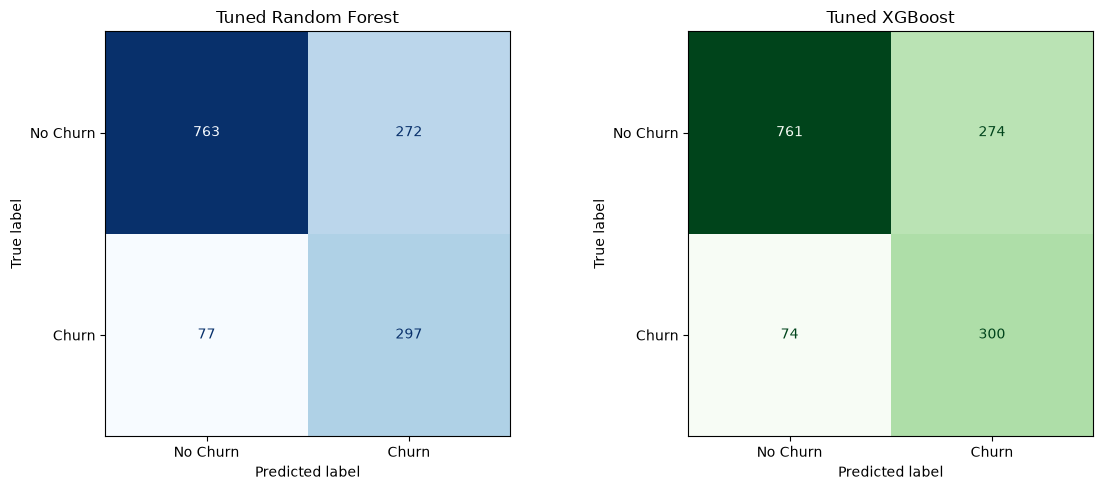

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrices
rf_cm = confusion_matrix(y_test, rf_pred, labels=["No", "Yes"])
xgb_cm = confusion_matrix(y_test, xgb_pred_labels, labels=["No", "Yes"])

# Plot both matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    rf_cm,
    display_labels=["No Churn", "Churn"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Tuned Random Forest")

ConfusionMatrixDisplay(
    xgb_cm,
    display_labels=["No Churn", "Churn"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Tuned XGBoost")

plt.tight_layout()
plt.savefig("../results/tuned_models_confusion_matrices.png", dpi=300)
plt.show()

In [29]:
# Extract the fitted preprocessing pipeline
best_preprocessor = best_xgb.named_steps["preprocessor"]

# Get transformed feature names
feature_names = best_preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importance_scores = best_xgb.named_steps["classifier"].feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
top_10_features = feature_importance.head(10)

display(top_10_features)

,Feature,Importance
36,cat__Contract_Month-to-month,0.360385
18,cat__OnlineSecurity_No,0.067892
38,cat__Contract_Two year,0.064144
16,cat__InternetService_Fiber optic,0.062863
27,cat__TechSupport_No,0.041824
37,cat__Contract_One year,0.033845
15,cat__InternetService_DSL,0.023636
43,cat__PaymentMethod_Electronic check,0.021657
35,cat__StreamingMovies_Yes,0.020550
1,num__tenure,0.020548


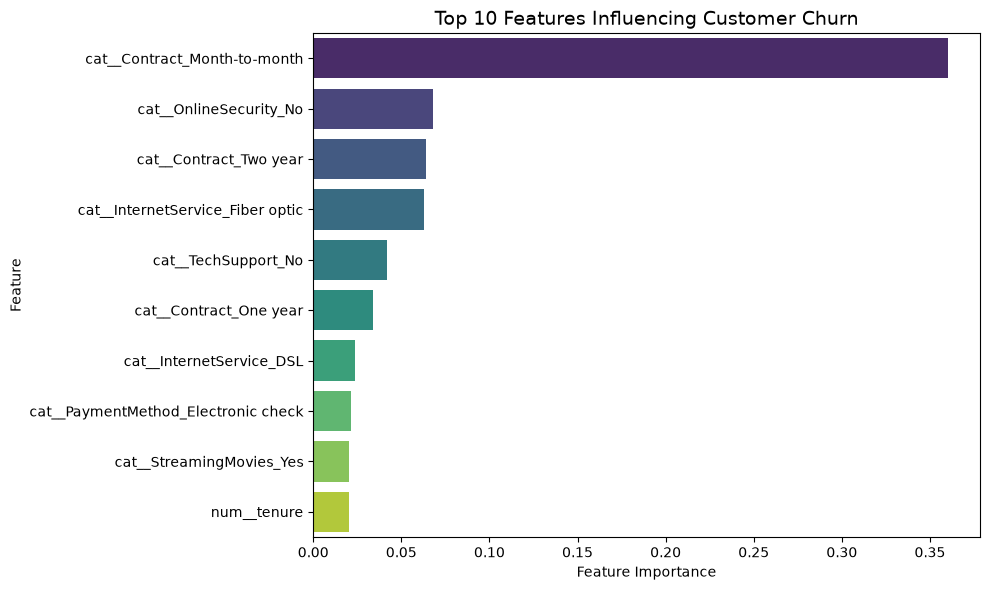

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Features Influencing Customer Churn", fontsize=14)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig("../results/top10_xgboost_feature_importance.png", dpi=300)
plt.show()

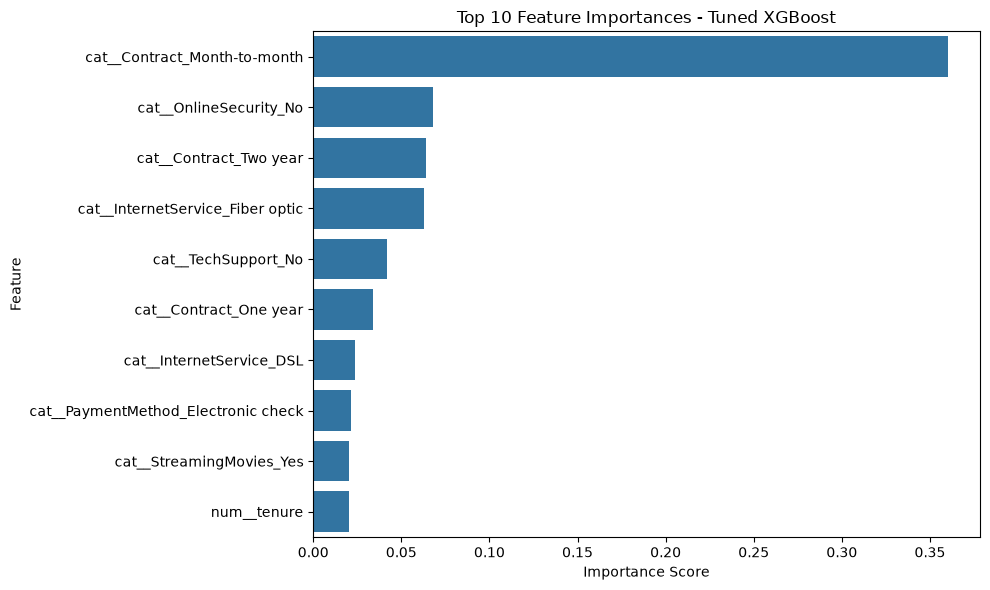

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Tuned XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../results/top10_xgboost_feature_importance.png",
    dpi=300
)

plt.show()

In [32]:
feature_importance.to_csv(
    "../results/xgboost_feature_importance.csv",
    index=False
)

print("Feature importance results saved successfully!")

Feature importance results saved successfully!


In [35]:
print([name for name in globals() if "comparison" in name.lower()])

[]


In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

comparison_df = pd.DataFrame([
    {
        "Model": "Tuned Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, pos_label="Yes"),
        "Recall": recall_score(y_test, rf_pred, pos_label="Yes"),
        "F1-Score": f1_score(y_test, rf_pred, pos_label="Yes"),
        "ROC-AUC": roc_auc_score(y_test_binary, rf_proba)
    },
    {
        "Model": "Tuned XGBoost",
        "Accuracy": accuracy_score(y_test.map({"No": 0, "Yes": 1}), xgb_pred),
        "Precision": precision_score(y_test_binary, xgb_pred),
        "Recall": recall_score(y_test_binary, xgb_pred),
        "F1-Score": f1_score(y_test_binary, xgb_pred),
        "ROC-AUC": roc_auc_score(y_test_binary, xgb_proba)
    }
])

display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.752307,0.521968,0.794118,0.629905,0.841578
1,Tuned XGBoost,0.753016,0.522648,0.802139,0.632911,0.848375


In [37]:
comparison_df.to_csv(
    "../results/tuned_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!
